In [43]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])
from matplotlib.pyplot import (
    text,
    axvline,
    figure,
    legend,
    savefig,
    rcParams,
    gca,
    show,
)

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [83]:
# load file
d_VT = {}  # dictionary of variable temperature ESR nddata
for k, fname in [
    # 20 mM TEMPO-SO4 in isooctane $w_0=20$
    # 240220 data 20 mM TEMPO-SO4 in isooctane $w_0=20$ 
    (
        "d_cooling_240220",
        "240220_TempoSO4_W20_run1.DSC",
        # Sample name: 240220 data w20 cooling
    ),
    (
        "d_reheating_240220",
        "240220_TempoSO4_W20_run1.DSC",
        # Sample name: 240220 data w20 reheating
    ),
]:
    d_VT[k] = find_file(fname, exp_type="francklab_esr/romana")
    d_VT[k] = d_VT[k].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]
    d_VT[k].reorder('Temperature').sort('Temperature')

d_RT = {} # dictionary of room temperature ESR nddata
for k, fname in [
    # 20 mM TEMPO-SO4 in isooctane $w_0=20$
    (
        "250324_OldTSO4_OldAOT",
        "250324_OldAOT_OldTSO4.DSC",
        # Sample name: 250324: Old TSO4 + Old AOT
    ),
    (
        "250324_NewTSO4_NewAOT",
        "250324_NewAOT_NewTSO4.DSC",
        # Sample name: 250324: New TSO4 + New AOT
    ),
    (
        "250324_OldTSO4_NaOH_OldAOT",
        "250324_OldAOT_OldTSO4_NaOH.DSC",
        # Sample name: 250324: Old TSO4 (NaOH) + Old AOT
    ),
    (
        "250324_OldTSO4_HCl_OldAOT",
        "250324_OldAOT_OldTSO4_HCl.DSC",
        # Sample name: 250324: Old TSO4 (HCl) + Old AOT
    ),
    (
        "250324_NewTSO4_OldAOT",
        "250324_OldAOT_NewTSO4.DSC",
        # Sample name: 250324: New TSO4 + Old AOT
    ),
    (
        "250324_OldTSO4_NewAOT",
        "250324_NewAOT_OldTSO4.DSC",
        # Sample name: 250324: Old TSO4 + New AOT
    ),
    # QESR 
    (
        "d_QESR_250303",
        "250305_20mM_TSO4_water.DSC",
        # Sample name: (Broad) QESR of 20 mM TEMPO-SO4 prepared 250303
    ),
    (
        "d_QESR_old_231121",
        "250305_20mM_TSO4_water_lastYears.DSC",
        # Sample name: (Control) QESR of old 20 mM TEMPO-SO4 prepared 231121
    ),
    ## water loading series
    (
        "d_w0_230726",
        "230726_TEMPO_SO4_W0.DSC",
        # Sample name: 230726: 0.5mM TSO4 w0 = 0
    ),
    (
        "d_w2_230726",
        "230726_TEMPO_SO4_W2.DSC",
        # Sample name: 230726: 0.5mM TSO4 w0 = 2
    ),
    (
        "d_w10_230726",
        "230726_TEMPO_SO4_W10.DSC",
        # Sample name: 230726: 0.5mM TSO4 w0 = 10
    ),
    (
        "d_w25_230726",
        "230726_TEMPO_SO4_W25.DSC",
        # Sample name: 230726: 0.5mM TSO4 w0 = 25
    ),
    (
        "d_w50_230726",
        "230726_TEMPO_SO4_W50.DSC",
        # Sample name: 230726: 0.5mM TSO4 w0 = 50
    ),
    ## water loading 250113
    (
        "d_w1_250113",
        "250113_20mM_TSO4_W1_Syn2.DSC",
        # Sample name: 250113: 20mM TSO4 w0 = 1
    ),
    (
        "d_w3_250113",
        "250113_20mM_TSO4_W3_Syn2.DSC",
        # Sample name: 250113: 20mM TSO4 w0 = 1
    ),
]:
    d_RT[k] = find_file(fname, exp_type="francklab_esr/romana")
    d_RT[k] = d_RT[k].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]

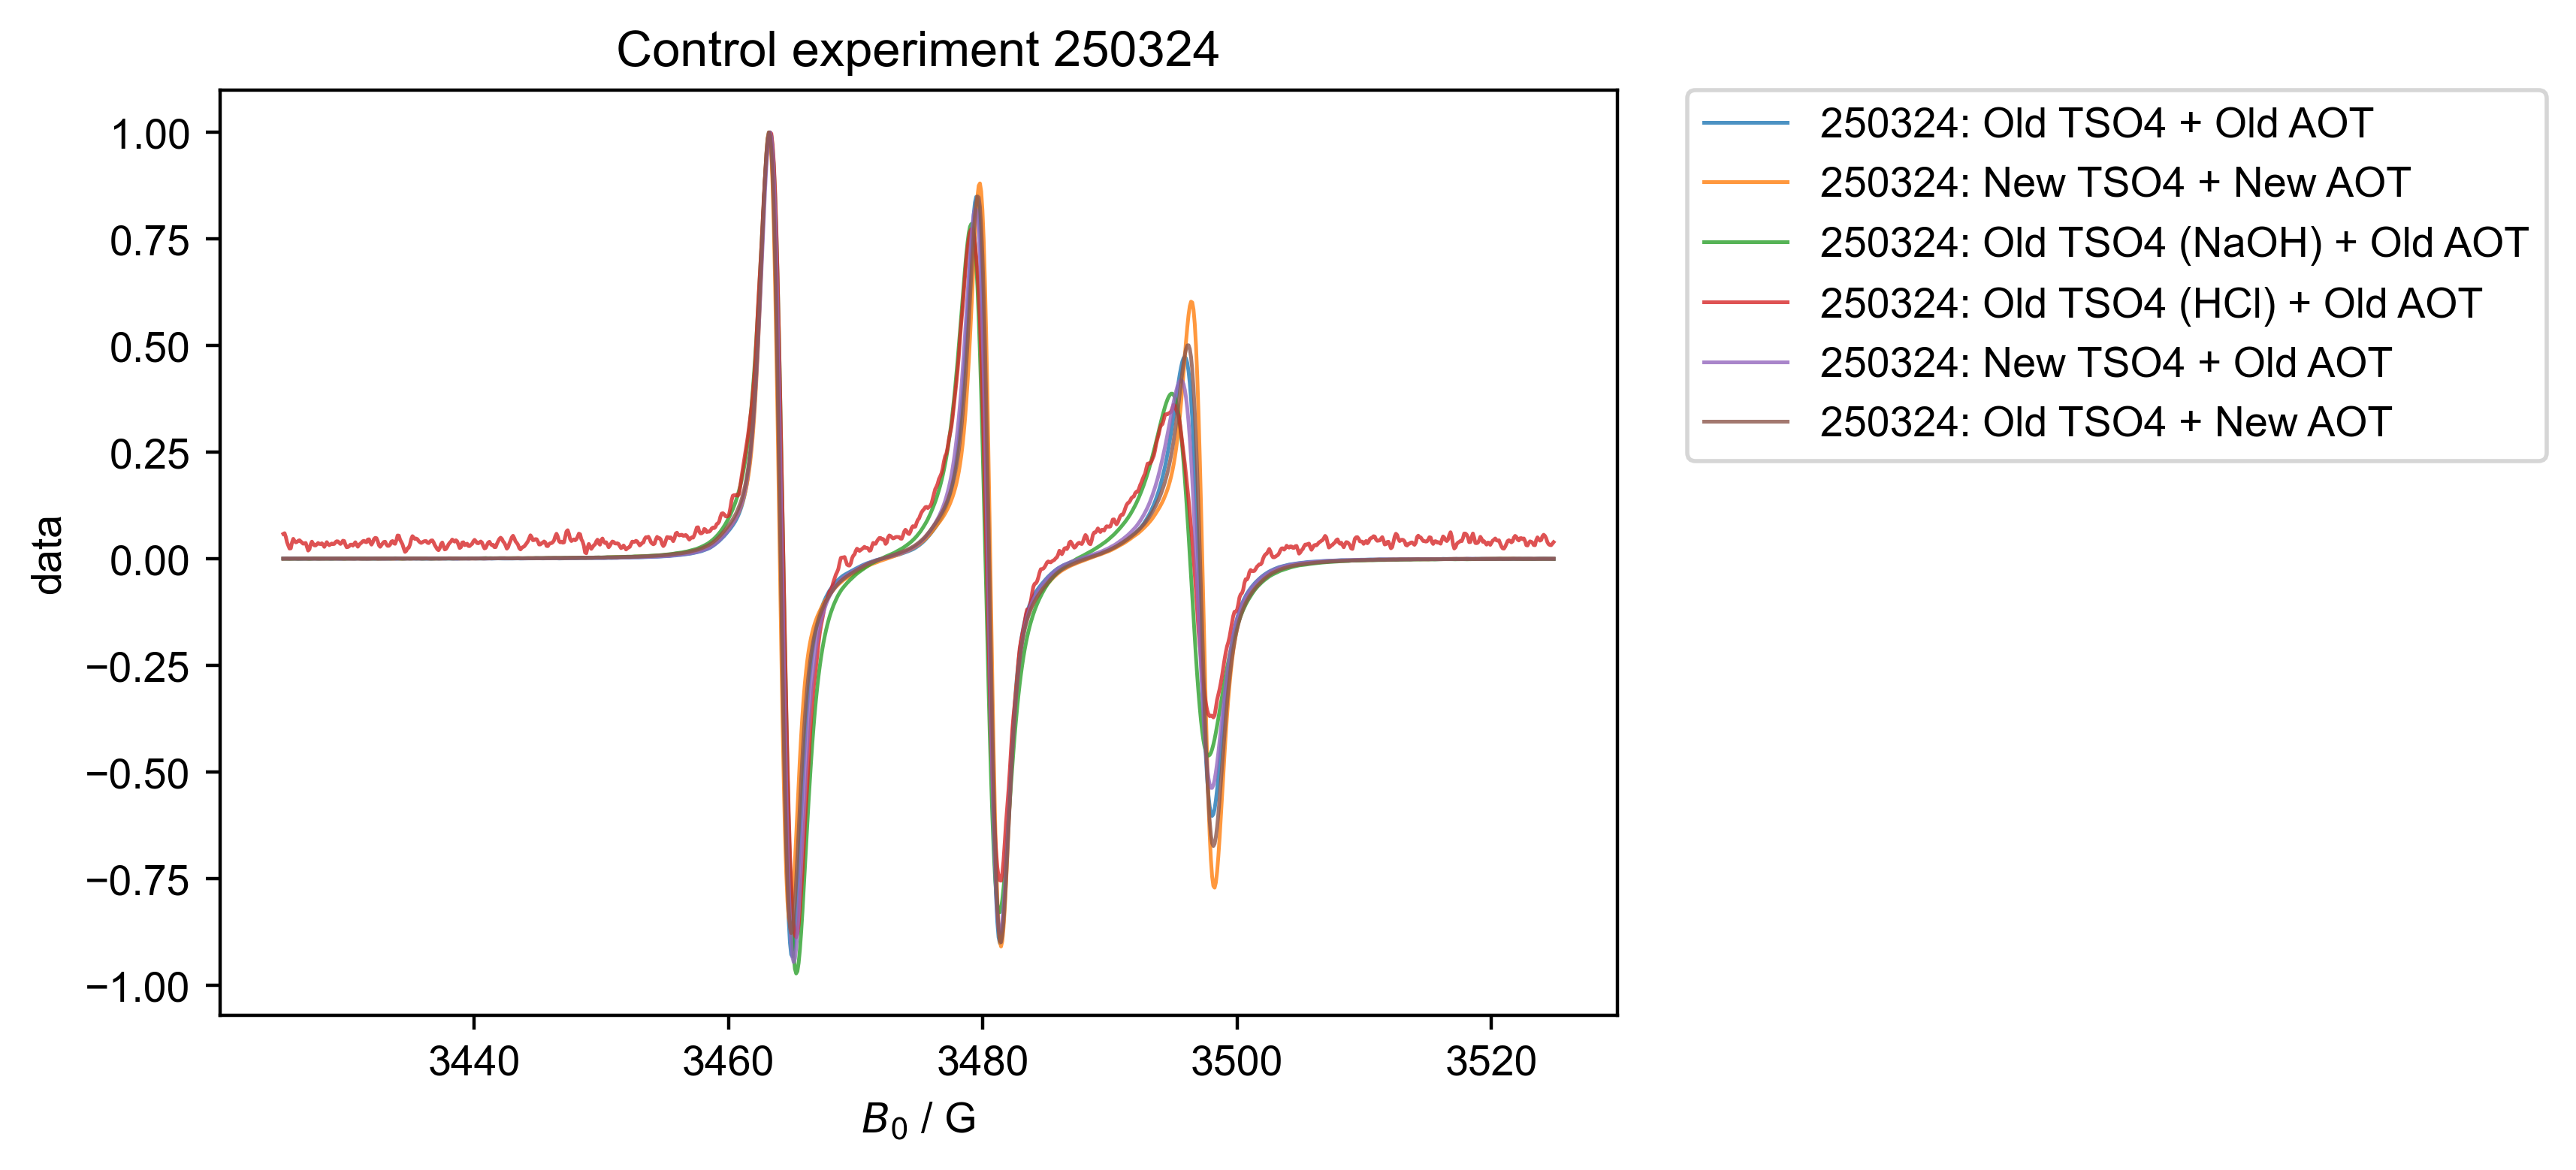

In [75]:
# Plot normalized
figure(dpi=400, figsize=(6,4)),
for k, thislabel in [
    ("250324_OldTSO4_OldAOT", r"250324: Old TSO4 + Old AOT"),
    ("250324_NewTSO4_NewAOT", r"250324: New TSO4 + New AOT"),
    ("250324_OldTSO4_NaOH_OldAOT", r"250324: Old TSO4 (NaOH) + Old AOT"),
    ("250324_OldTSO4_HCl_OldAOT", r"250324: Old TSO4 (HCl) + Old AOT"),
    ("250324_NewTSO4_OldAOT", r"250324: New TSO4 + Old AOT"),
    ("250324_OldTSO4_NewAOT", r"250324: Old TSO4 + New AOT"),   
]:
    d_RT[k] = d_RT[k]["$B_0$":(3400, 3550)]
    plot(
        d_RT[k]/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
gca().set_title(r"Control experiment 250324"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside\
show()

3479.4921876363637
3479.4921876363637
3479.785156387097
3479.785156387097
3479.394531386119
3479.394531386119
3479.589843886608
3479.589843886608
3365.5664063890517
3365.5664063890517


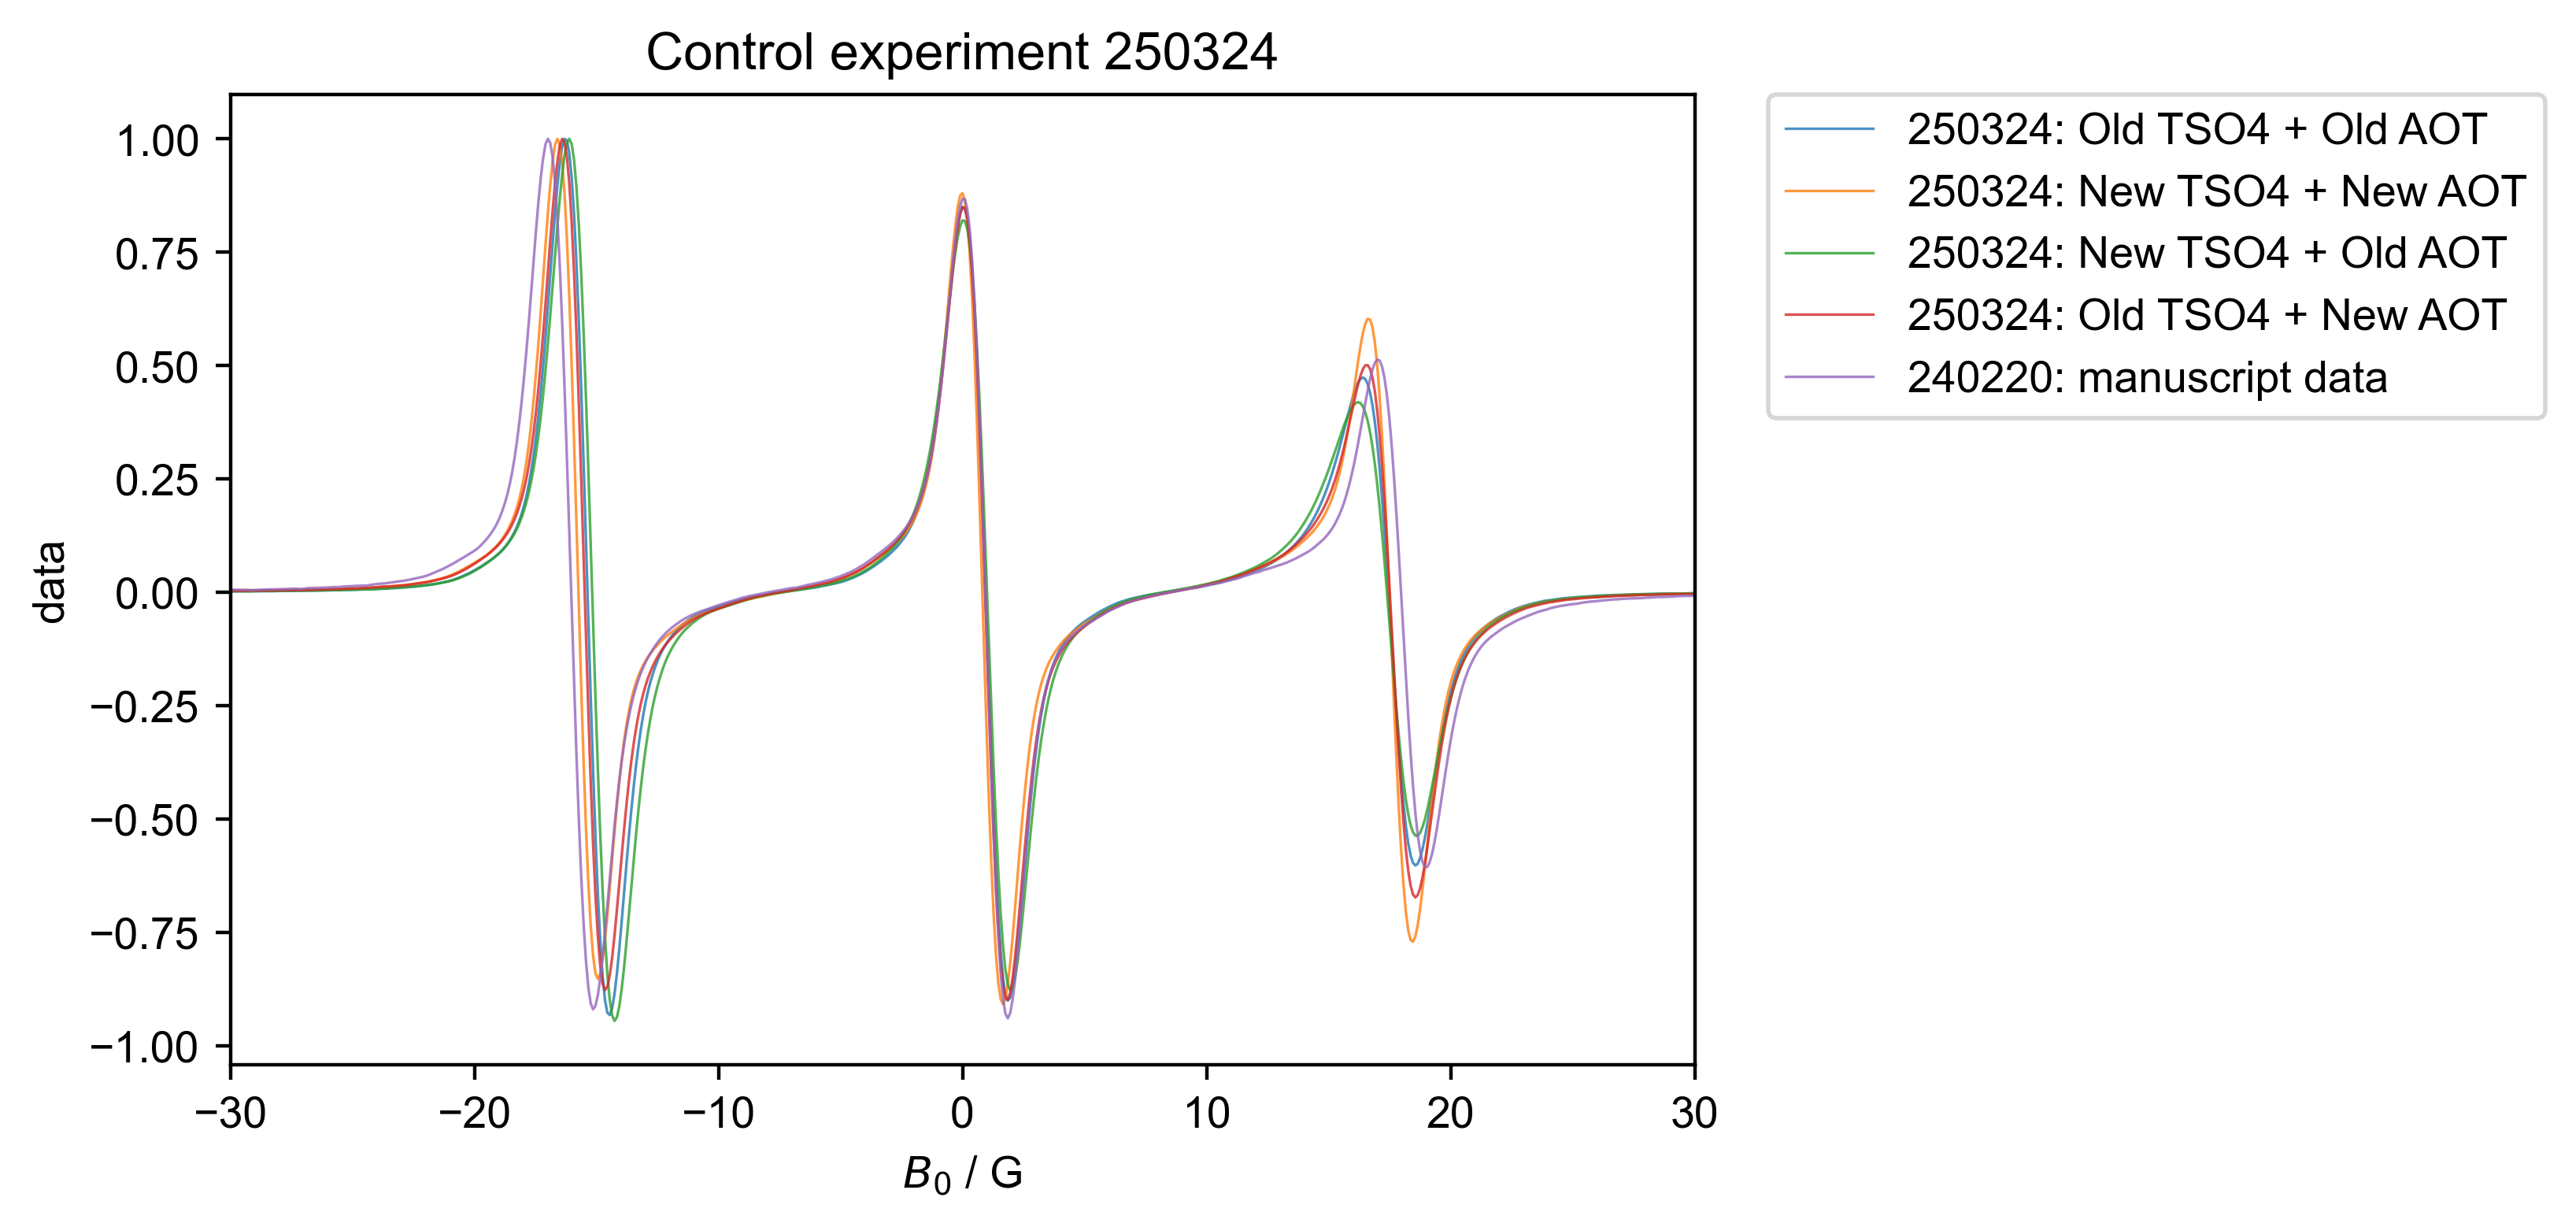

In [60]:
# Plot Aliged normalized
figure(dpi=400, figsize=(6,4)),
for k, thislabel in [
    ("250324_OldTSO4_OldAOT", r"250324: Old TSO4 + Old AOT"),
    ("250324_NewTSO4_NewAOT", r"250324: New TSO4 + New AOT"),
    # ("250324_OldTSO4_NaOH_OldAOT", r"250324: Old TSO4 (NaOH) + Old AOT"),
    # ("250324_OldTSO4_HCl_OldAOT", r"250324: Old TSO4 (HCl) + Old AOT"),
    ("250324_NewTSO4_OldAOT", r"250324: New TSO4 + Old AOT"),
    ("250324_OldTSO4_NewAOT", r"250324: Old TSO4 + New AOT"),   
]:
    d_RT[k] = d_RT[k]["$B_0$":(3400, 3550)]
    thismax= d_RT[k]["$B_0$":(3470, 3490)].C.argmax().item()
    print(thismax)
    d_RT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_RT[k]/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.6,
    )
# VTU
for k, thislabel in [
    ("d_cooling_240220", r"240220: manuscript data"),
]:
    d_VT[k] = d_VT[k]["$B_0$":(3300, 3550)]["Temperature":293]
    thismax= d_VT[k]["$B_0$":(3360, 3370)].C.argmax().item()
    print(thismax)
    d_VT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_VT[k]/d_VT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.6,
    )
gca().set_title(r"Control experiment 250324"),
xlim(-30,30)
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside\
show()

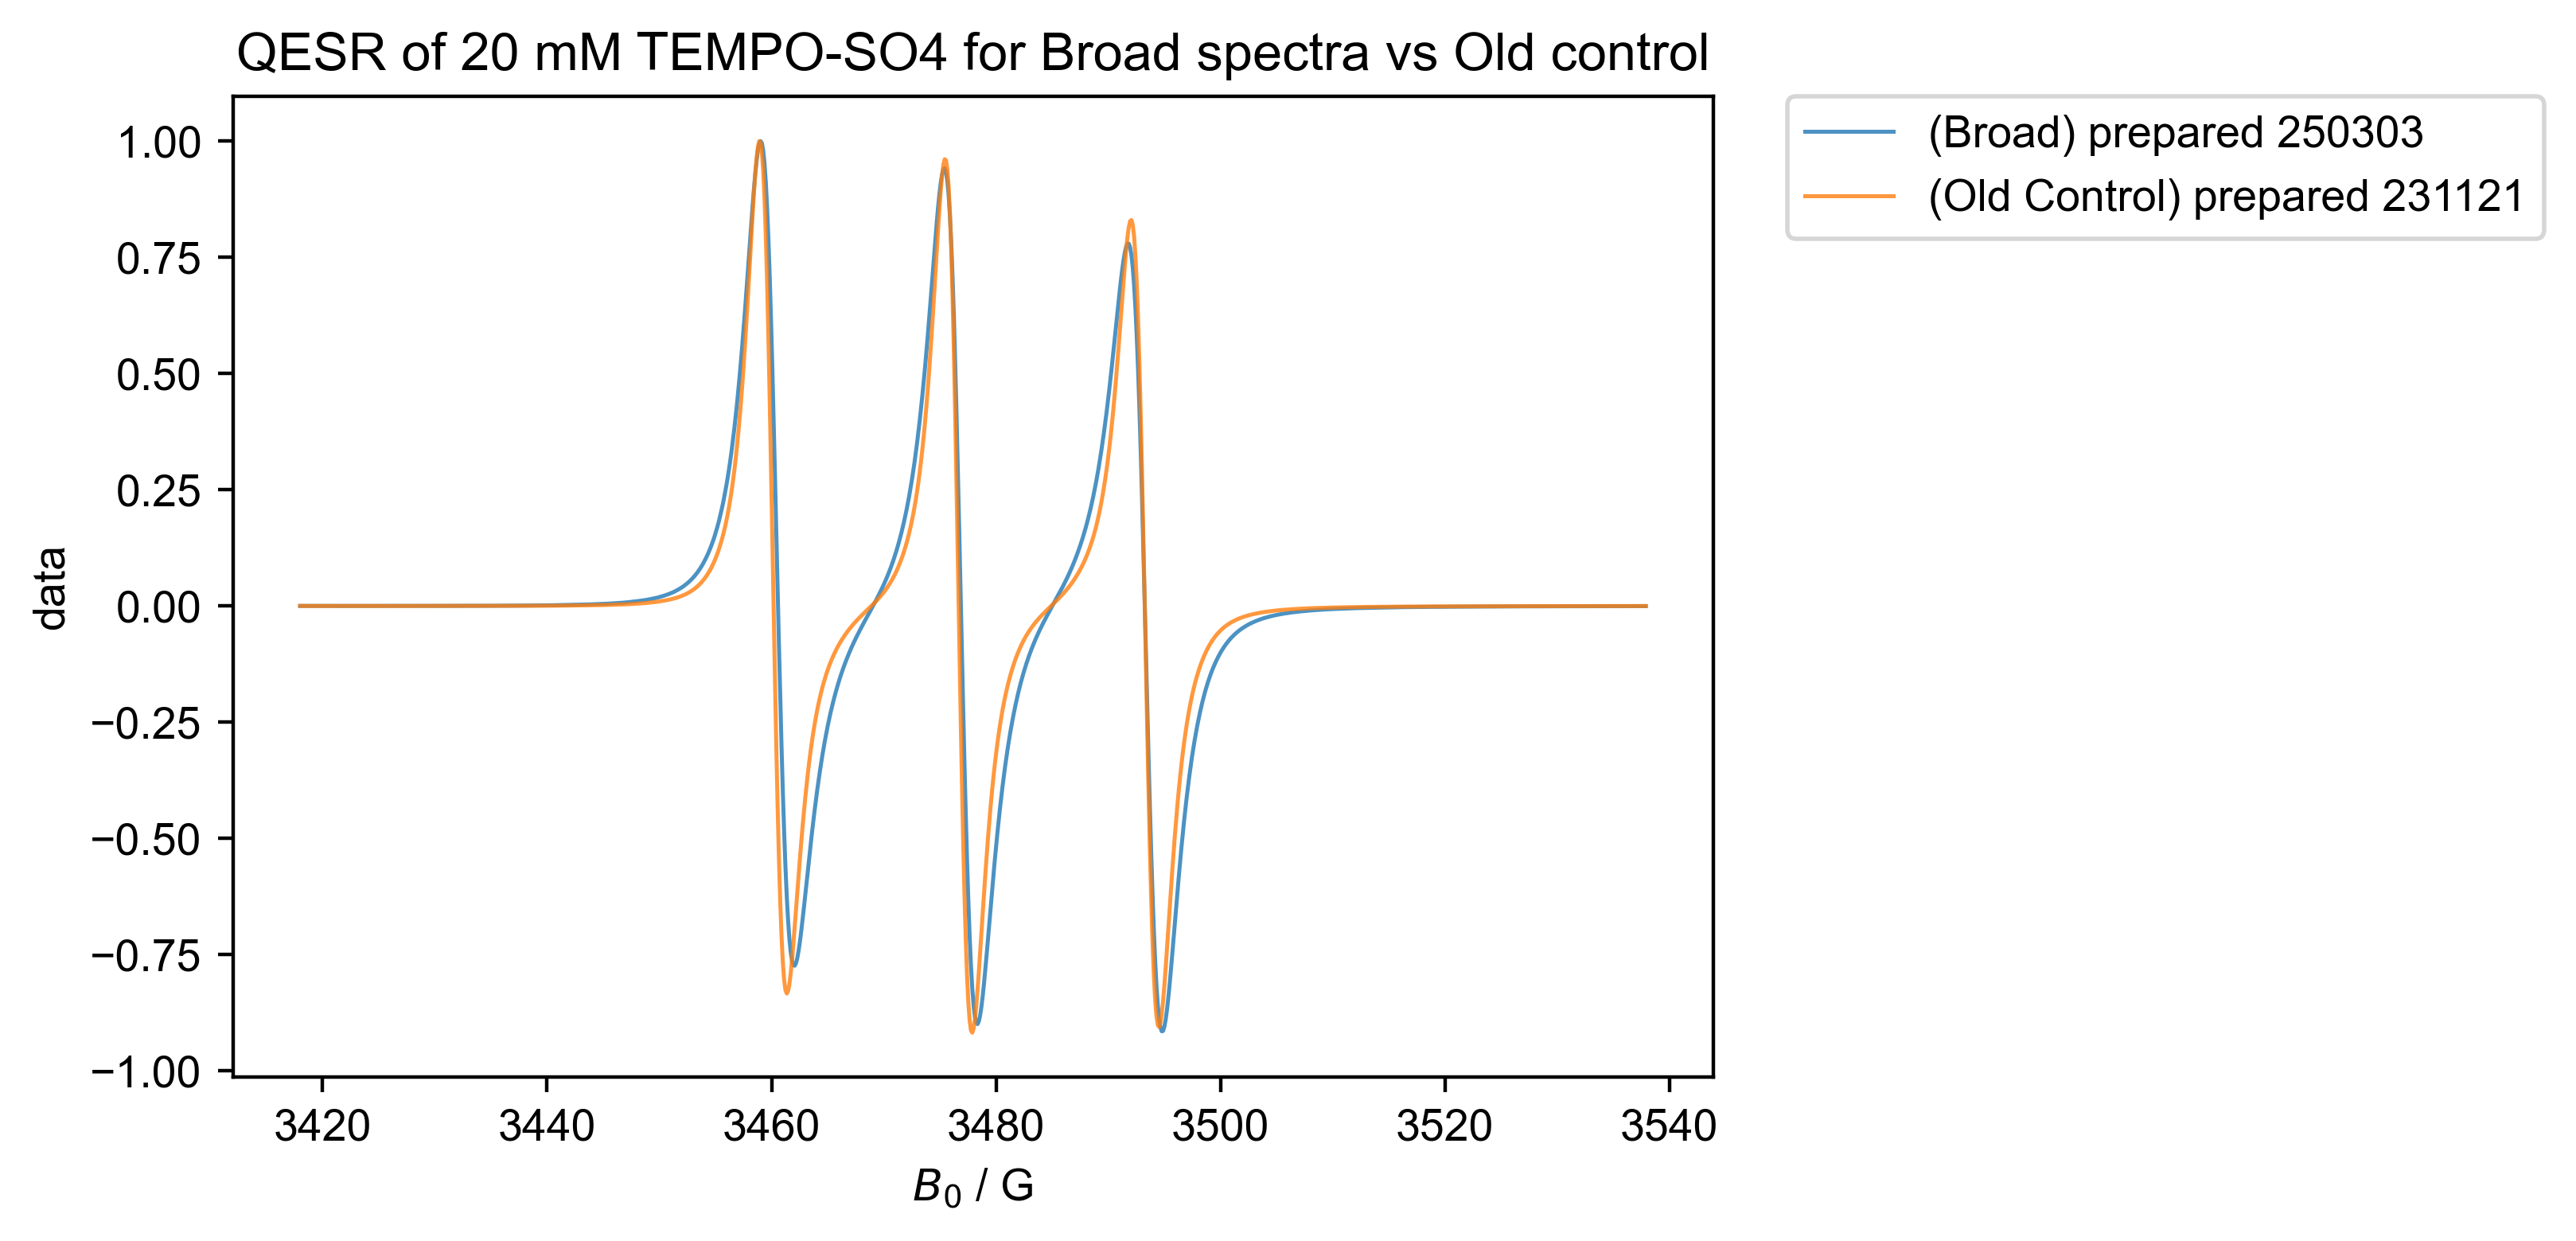

In [41]:
# QESR Plot normalized
figure(dpi=400, figsize=(6,4)),
for k, thislabel in [
    ("d_QESR_250303", r"(Broad) prepared 250303"),
    ("d_QESR_old_231121", r"(Old Control) prepared 231121"),  
]:
    d_RT[k] = d_RT[k]["$B_0$":(3400, 3550)]
    plot(
        d_RT[k]/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
gca().set_title(r"QESR of 20 mM TEMPO-SO4 for Broad spectra vs Old control"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside\
show()

3502.3771020515824
3502.3771020515824
3502.7363461166474
3502.7363461166474
3503.7911366207504
3503.7911366207504
3504.1427334554514
3504.1427334554514
3503.947436078546
3503.947436078546
3475.9465648137534
3475.9465648137534
3476.2328243553006
3476.2328243553006
3365.5664063890517
3365.5664063890517


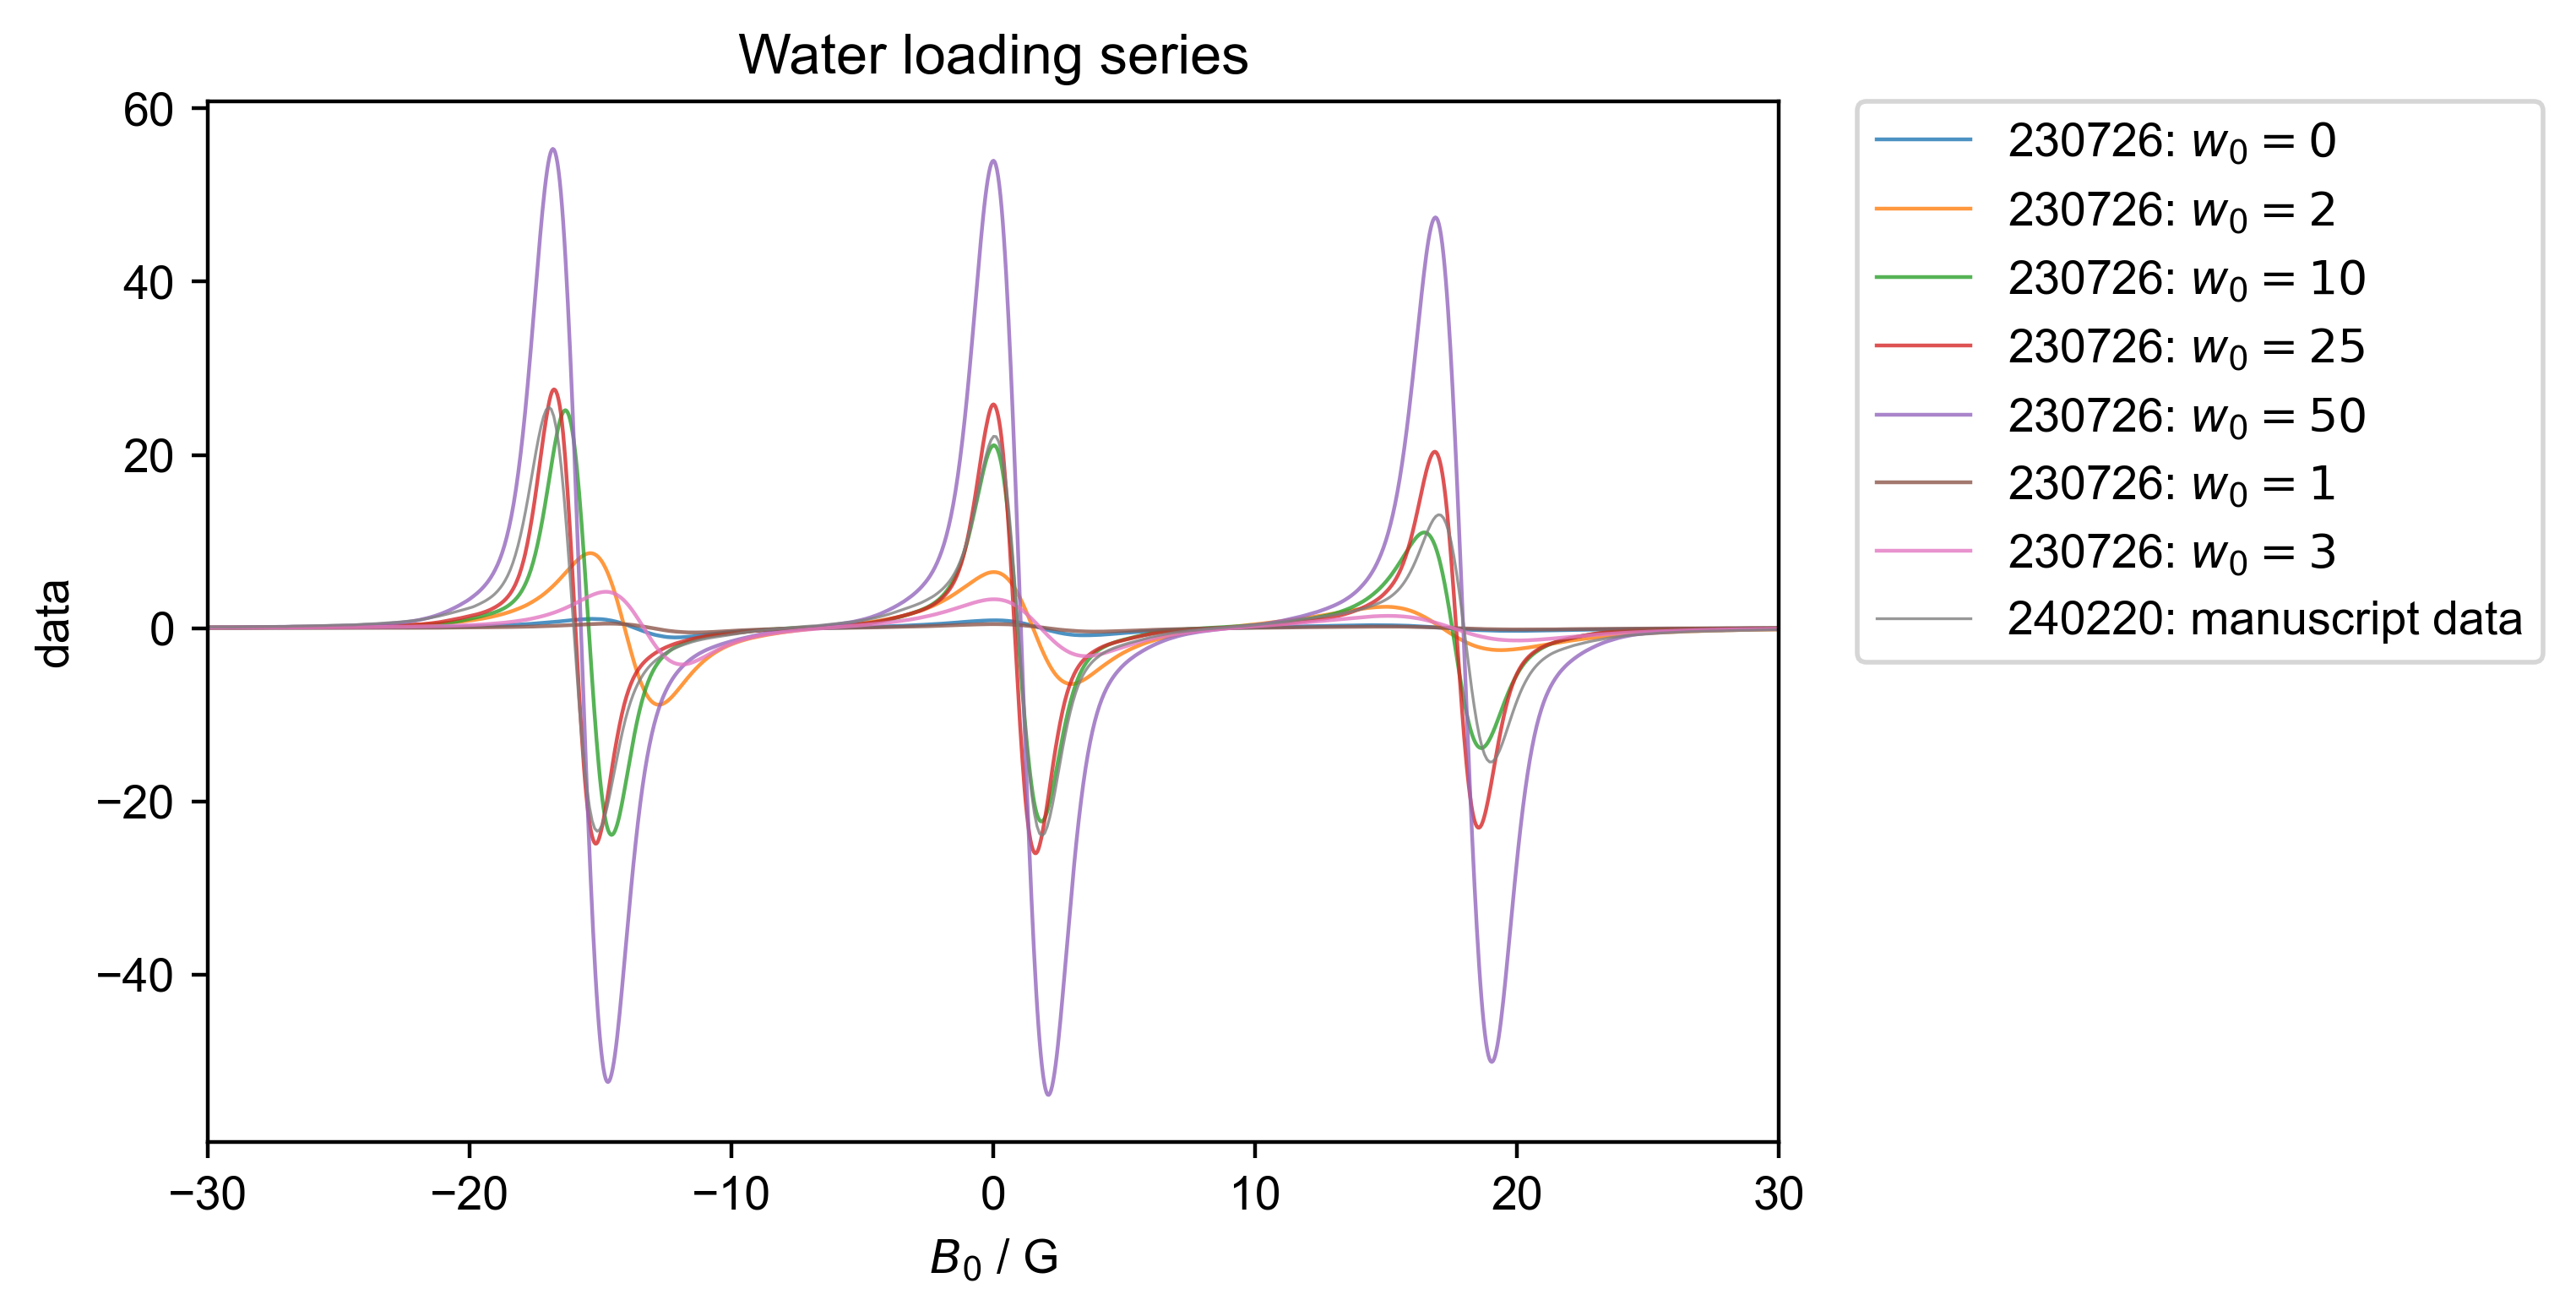

In [84]:
# water loading series
figure(dpi=400, figsize=(6,4)),
for k, thislabel in [
    ("d_w0_230726", r"230726: $w_0 =0$"),
    ("d_w2_230726", r"230726: $w_0 =2$"),
    ("d_w10_230726", r"230726: $w_0 =10$"),
    ("d_w25_230726", r"230726: $w_0 =25$"),
    ("d_w50_230726", r"230726: $w_0 =50$"),  
]:
    d_RT[k] = d_RT[k]["$B_0$":(3300, 3650)]
    thismax= d_RT[k]["$B_0$":(3500, 3510)].C.argmax().item()
    print(thismax)
    d_RT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_RT[k],#/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.8,
    )
for k, thislabel in [
    # 250113
    ("d_w1_250113", r"230726: $w_0 =1$"),
    ("d_w3_250113", r"230726: $w_0 =3$"),
  
]:
    d_RT[k] = d_RT[k]["$B_0$":(3300, 3650)]
    thismax= d_RT[k]["$B_0$":(3470, 3490)].C.argmax().item()
    print(thismax)
    d_RT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_RT[k],#/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.8,
    )
# #VTU
for k, thislabel in [
    ("d_cooling_240220", r"240220: manuscript data"),
]:
    d_VT[k] = d_VT[k]["$B_0$":(3300, 3550)]["Temperature":293]
    thismax= d_VT[k]["$B_0$":(3360, 3370)].C.argmax().item()
    print(thismax)
    d_VT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_VT[k],#/d_VT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.6,
    )
gca().set_title(r"Water loading series"),
xlim(-30,30)
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside\
show()

3502.3771020515824
3502.3771020515824
3502.7363461166474
3502.7363461166474
3503.7911366207504
3503.7911366207504
3504.1427334554514
3504.1427334554514
3503.947436078546
3503.947436078546
3475.9465648137534
3475.9465648137534
3476.2328243553006
3476.2328243553006
3365.5664063890517
3365.5664063890517


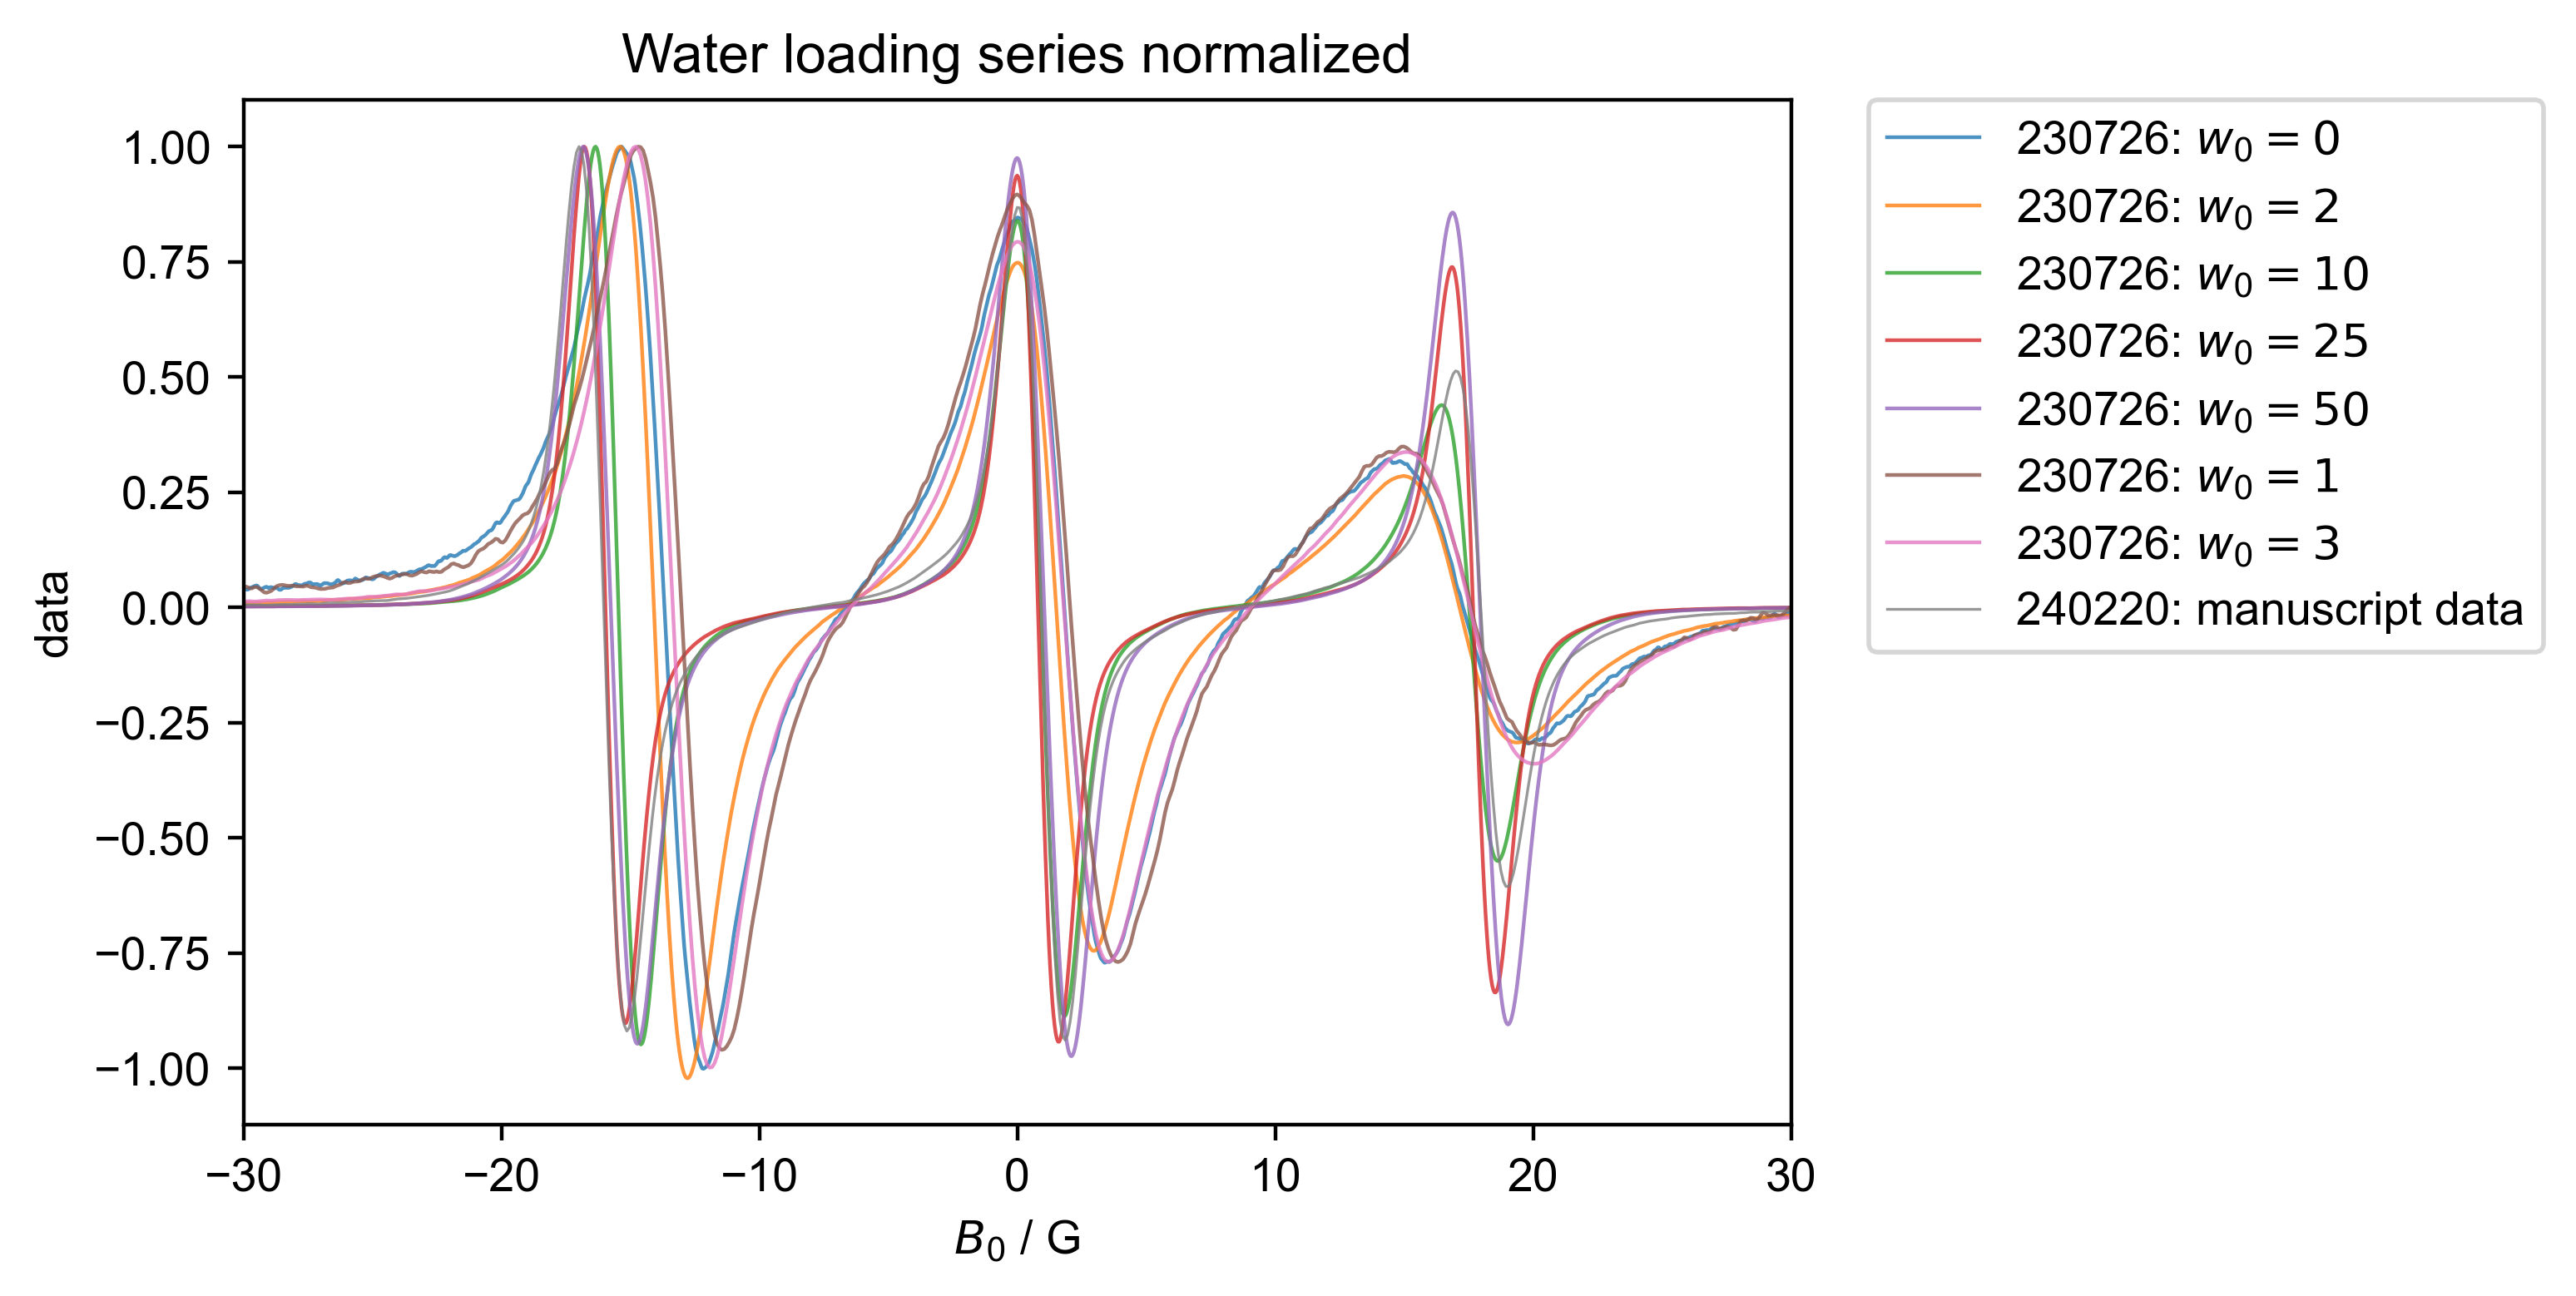

In [82]:
# water loading series
figure(dpi=400, figsize=(6,4)),
for k, thislabel in [
    ("d_w0_230726", r"230726: $w_0 =0$"),
    ("d_w2_230726", r"230726: $w_0 =2$"),
    ("d_w10_230726", r"230726: $w_0 =10$"),
    ("d_w25_230726", r"230726: $w_0 =25$"),
    ("d_w50_230726", r"230726: $w_0 =50$"),  
]:
    d_RT[k] = d_RT[k]["$B_0$":(3300, 3650)]
    thismax= d_RT[k]["$B_0$":(3500, 3510)].C.argmax().item()
    print(thismax)
    d_RT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_RT[k]/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.8,
    )
for k, thislabel in [
    # 250113
    ("d_w1_250113", r"230726: $w_0 =1$"),
    ("d_w3_250113", r"230726: $w_0 =3$"),
  
]:
    d_RT[k] = d_RT[k]["$B_0$":(3300, 3650)]
    thismax= d_RT[k]["$B_0$":(3470, 3490)].C.argmax().item()
    print(thismax)
    d_RT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_RT[k]/d_RT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.8,
    )
# #VTU
for k, thislabel in [
    ("d_cooling_240220", r"240220: manuscript data"),
]:
    d_VT[k] = d_VT[k]["$B_0$":(3300, 3550)]["Temperature":293]
    thismax= d_VT[k]["$B_0$":(3360, 3370)].C.argmax().item()
    print(thismax)
    d_VT[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d_VT[k]/d_VT[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.6,
    )
gca().set_title(r"Water loading series normalized"),
xlim(-30,30)
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside\
show()